# Week 6 Task 1: first climate gradient on an energy-balance model

LEAP book chapter 1.2 ([First climate gradient](https://leap-stc.github.io/diff-earth/part1/first-climate-gradient.html)):
differentiate a one-line energy-balance model with `jax.grad`, `jax.jvp` and `jax.vjp`, and check every derivative
against a finite difference. Then the chapter's three exercises.

**Answer.**

- **Forward and reverse mode agree.** `jax.grad`, `jax.jvp` and `jax.vjp` all give dT/dα = **−102.88 K per unit
  albedo**, equal to each other to the last bit and to the closed form −T/[4(1−α)] to 1e-16 relative. Both modes
  apply the chain rule exactly to the same chain of operations; they only multiply the factors in a different order.
- **Finite differences.** The error first falls, then rises as h shrinks: truncation error (∝ h², central) against
  round-off (∝ ε/h). The best central step is **h ≈ 4e-6 in float64 (error 2e-11 relative)** but
  **h ≈ 2e-3 in float32 (error 6e-6 relative)**, close to ε^(1/3) in each precision. Below h ≈ 1.5e-8, float32 can't
  represent α + h at all and the finite difference is exactly 0.
- **Exercises.** dT/dε = −118.1 K per unit emissivity (negative: a better emitter cools to the same outgoing flux at a
  lower T). d²T/dα² = −110.2 K: T is concave in albedo, so each extra 0.01 of albedo cools a little more than the last.
  `jax.jacfwd` and `jax.jacrev` give both partial derivatives at once and match.
- **For JCM (Tasks 2–4).** JCM runs in float32, so a finite difference there can't be trusted below about 1e-3 relative
  even on a smooth function. Steps of 1 K (or 0.1 K) on an SST near 290 K are 3e-3 (3e-4) relative, both below this
  smooth function's float32 optimum (≈5e-3), so round-off can be part of an FD-vs-gradient gap at h = 0.1 K.

Figure: `figures/week6_task1_fd_error.png`. Kernel `jcm` (no model needed); runs in a few seconds.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

# float64 by default, as in the chapter. Section 3 casts inputs to float32 explicitly: Python-float constants are
# weakly typed, so a float32 input keeps the whole calculation in float32.
jax.config.update("jax_enable_x64", True)

## 1. The model

Grey-body radiative equilibrium for the global-mean surface temperature:

$$T_\mathrm{eq} = \left[\frac{S_0(1-\alpha)}{4\varepsilon\sigma}\right]^{1/4}$$

with $S_0 = 1361$ W m⁻², albedo $\alpha = 0.30$, emissivity $\varepsilon = 0.61$ and
$\sigma = 5.67\times10^{-8}$ W m⁻² K⁻⁴ (the chapter's values).

In [2]:
S0, SIGMA = 1361.0, 5.67e-8
ALBEDO, EMISSIVITY = 0.30, 0.61

def equilibrium_temperature(albedo, emissivity=EMISSIVITY):
    return (S0 * (1 - albedo) / (4 * emissivity * SIGMA)) ** 0.25

T0 = equilibrium_temperature(ALBEDO)
print(f"T_eq = {T0:.2f} K")

T_eq = 288.07 K


## 2. Three ways to take dT/dα

- `jax.grad`: the derivative of a scalar function.
- `jax.jvp` (forward mode, tangent-linear model): push an input perturbation $\delta\alpha$ forward and get
  $\delta T = (\partial T/\partial\alpha)\,\delta\alpha$.
- `jax.vjp` (reverse mode, adjoint model): pull an output sensitivity $\bar T$ backward and get
  $\bar\alpha = \bar T\,(\partial T/\partial\alpha)$.

Closed form: $\partial T/\partial\alpha = -T/[4(1-\alpha)]$.

In [3]:
dT_grad = jax.grad(equilibrium_temperature)(ALBEDO)
dT_exact = -T0 / (4 * (1 - ALBEDO))

# Forward mode: the response to +0.01 of albedo, and to a unit tangent (the derivative itself)
_, dT_plus001 = jax.jvp(equilibrium_temperature, (ALBEDO,), (0.01,))
_, dT_jvp = jax.jvp(equilibrium_temperature, (ALBEDO,), (1.0,))

# Reverse mode: seed the output with dT/dT = 1
_, backward = jax.vjp(equilibrium_temperature, ALBEDO)
(dT_vjp,) = backward(1.0)

print(f"closed form   {dT_exact:.10f} K per unit albedo")
print(f"jax.grad      {dT_grad:.10f}")
print(f"jax.jvp (1)   {dT_jvp:.10f}")
print(f"jax.vjp (1)   {dT_vjp:.10f}")
print(f"jvp with +0.01 of albedo: dT = {dT_plus001:.4f} K")
print(f"max |difference| between the three autodiff values: "
      f"{max(abs(dT_grad - dT_jvp), abs(dT_grad - dT_vjp), abs(dT_jvp - dT_vjp)):.1e}")
print(f"relative error against the closed form: {abs(dT_grad - dT_exact) / abs(dT_exact):.1e}")

closed form   -102.8816186994 K per unit albedo
jax.grad      -102.8816186994
jax.jvp (1)   -102.8816186994
jax.vjp (1)   -102.8816186994
jvp with +0.01 of albedo: dT = -1.0288 K
max |difference| between the three autodiff values: 0.0e+00
relative error against the closed form: 1.4e-16


**Why forward and reverse mode give the same number.** Both apply the chain rule exactly to the same chain of
elementary operations. The model is $T = g_4(g_3(g_2(g_1(\alpha))))$ (subtract, multiply, divide, fourth root), so
$dT/d\alpha = g_4' \cdot g_3' \cdot g_2' \cdot g_1'$. Forward mode multiplies these factors starting from the input
end, carrying $\delta\alpha$ along; reverse mode multiplies them starting from the output end, carrying $\bar T$
back. Multiplication is associative, so the product is the same, and here both are the single entry of a 1×1
Jacobian. Any difference is float rounding from doing the multiplications in a different order (above: zero, or
a few units in the last place). Neither is an approximation: there is no step size.

## 3. Finite differences: the error first falls, then rises

Central difference $[f(\alpha+h) - f(\alpha-h)]/2h$ and one-sided difference $[f(\alpha+h) - f(\alpha)]/h$,
compared with the exact derivative, for $h$ from 1e-1 down to 1e-13, in float64 and in float32 (JCM's default).

First the chapter's table (float64, central difference):

In [4]:
def central(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def one_sided(f, x, h):
    return (f(x + h) - f(x)) / h

for h in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]:
    print(f"h = {h:.0e}   |FD - autodiff| = {abs(central(equilibrium_temperature, ALBEDO, h) - dT_grad):.2e}")

h = 1e-02   |FD - autodiff| = 4.59e-03
h = 1e-04   |FD - autodiff| = 4.59e-07
h = 1e-06   |FD - autodiff| = 1.19e-08
h = 1e-08   |FD - autodiff| = 1.32e-06
h = 1e-10   |FD - autodiff| = 1.46e-04


Two errors compete:

- **Truncation error** (the Taylor series terms the formula leaves out) shrinks with $h$:
  about $|f''|\,h/2$ one-sided and $|f'''|\,h^2/6$ central.
- **Round-off error** grows as $h$ shrinks: $f(\alpha \pm h)$ are each rounded to a relative precision
  $\epsilon$ (machine epsilon), and their difference, of size $f' h$, is divided by $h$. This gives about
  $\epsilon\,|f|/h$.

The total is smallest where the two are equal: $h^* \sim \sqrt{\epsilon}$ one-sided and
$h^* \sim \epsilon^{1/3}$ central (times factors of order 1 that depend on $f$). The dashed lines below are this
error model for the central difference, with $f''$ and $f'''$ from nested `jax.grad`.

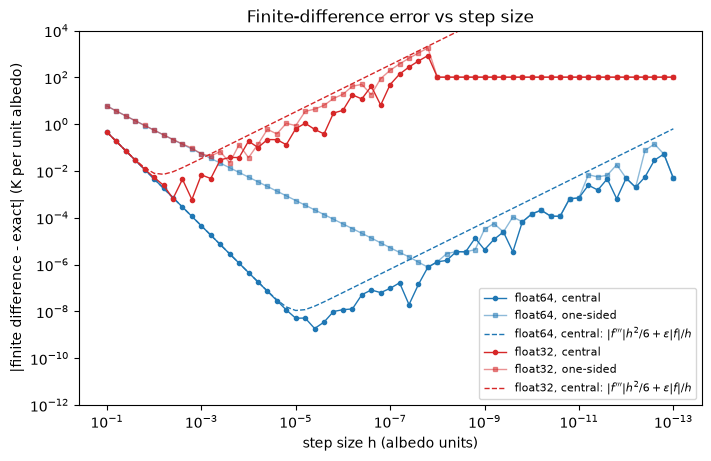

float64  central   best h = 4e-06, error = 1.9e-09 (2e-11 relative)
float64  one-sided best h = 2e-08, error = 7.8e-07 (8e-09 relative)
float32  central   best h = 2e-03, error = 6.1e-04 (6e-06 relative)
float32  one-sided best h = 3e-04, error = 2.3e-02 (2e-04 relative)
float64: eps = 2.2e-16, sqrt(eps) = 1e-08, eps^(1/3) = 6e-06
float32: eps = 1.2e-07, sqrt(eps) = 3e-04, eps^(1/3) = 5e-03


In [5]:
hs = np.logspace(-1, -13, 61)
d2 = jax.grad(jax.grad(equilibrium_temperature))(ALBEDO)
d3 = jax.grad(jax.grad(jax.grad(equilibrium_temperature)))(ALBEDO)

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
best = {}
for dtype, color in [(jnp.float64, "C0"), (jnp.float32, "C3")]:
    name = jnp.dtype(dtype).name
    x = jnp.asarray(ALBEDO, dtype)
    eps = float(jnp.finfo(dtype).eps)
    for scheme, fd, style in [("central", central, "o-"), ("one-sided", one_sided, "s-")]:
        # Error against the exact (float64) derivative. Steps below float32 resolution give FD = 0 (error = |f'|).
        err = np.array([abs(float(fd(equilibrium_temperature, x, jnp.asarray(h, dtype))) - float(dT_exact))
                        for h in hs])
        err = np.maximum(err, 1e-16)  # exact zeros would vanish on a log axis
        ax.loglog(hs, err, style, color=color, ms=3, lw=1, alpha=1 if scheme == "central" else 0.5,
                  label=f"{name}, {scheme}")
        best[name, scheme] = (hs[np.argmin(err)], err.min())
    model = abs(d3) * hs**2 / 6 + eps * abs(T0) / hs
    ax.loglog(hs, model, "--", color=color, lw=1, label=f"{name}, central: $|f'''|h^2/6 + \\epsilon|f|/h$")

ax.set(xlabel="step size h (albedo units)", ylabel="|finite difference - exact| (K per unit albedo)",
       title="Finite-difference error vs step size", ylim=(1e-12, 1e4))
ax.invert_xaxis()
ax.legend(fontsize=8)
plt.savefig("../figures/week6_task1_fd_error.png", dpi=120)
plt.show()

for (name, scheme), (h, e) in best.items():
    print(f"{name:8s} {scheme:9s} best h = {h:.0e}, error = {e:.1e} ({e / abs(dT_exact):.0e} relative)")
for name, eps in [("float64", np.finfo(np.float64).eps), ("float32", np.finfo(np.float32).eps)]:
    print(f"{name}: eps = {eps:.1e}, sqrt(eps) = {eps**0.5:.0e}, eps^(1/3) = {eps**(1/3):.0e}")

The float64 central-difference error reproduces the chapter's table exactly. Reading the plot:

- **Right to left, the error first falls** along the truncation slope (slope 2 for central, 1 for one-sided), **then
  rises** with slope −1 once round-off dominates. Both precisions follow the dashed error model to within a factor
  of a few; the scatter on the round-off side is the random part of rounding.
- **The best step depends on the precision.** Central: h ≈ 4e-6 in float64 (ε^(1/3) = 6e-6), h ≈ 2e-3 in float32
  (ε^(1/3) = 5e-3). One-sided: h ≈ 2e-8 (√ε = 1e-8) and 3e-4 (√ε = 3e-4). The best one-sided result is always worse
  than the best central one.
- **float32 loses most of the digits.** The best central difference is good to 6e-6 relative, against 2e-11 in
  float64. For h below about 1.5e-8 (half the float32 spacing at 0.30, which is 3e-8), α ± h rounds back to α, so the difference is exactly
  zero and the error equals the whole derivative (the flat line at 103).

## 4. Exercises

### Exercise 1: dT/dε, checked against a finite difference

Closed form: $\partial T/\partial\varepsilon = -T/(4\varepsilon)$.

In [6]:
dT_deps = jax.grad(equilibrium_temperature, argnums=1)(ALBEDO, EMISSIVITY)
fd_eps = (equilibrium_temperature(ALBEDO, EMISSIVITY + 1e-5)
          - equilibrium_temperature(ALBEDO, EMISSIVITY - 1e-5)) / 2e-5
print(f"jax.grad        {dT_deps:.8f} K per unit emissivity")
print(f"closed form     {-T0 / (4 * EMISSIVITY):.8f}")
print(f"central FD 1e-5 {fd_eps:.8f}   (relative difference {abs(fd_eps - dT_deps) / abs(dT_deps):.0e})")
print(f"so +0.01 of emissivity changes T by {0.01 * dT_deps:.2f} K")

jax.grad        -118.06087392 K per unit emissivity
closed form     -118.06087392
central FD 1e-5 -118.06087393   (relative difference 1e-10)
so +0.01 of emissivity changes T by -1.18 K


**dT/dε = −118.1 K per unit emissivity**, equal to the closed form; the central difference agrees to 1e-10 relative.
The sign is what we expect: the surface has to emit $S_0(1-\alpha)/4 \approx 238$ W m⁻² to balance absorbed sunlight,
and a higher ε means it emits that at a lower temperature (in this model ε stands in for the greenhouse effect, so a
*smaller* ε is a stronger greenhouse effect and a warmer surface). The magnitude: −0.01 of ε warms by 1.18 K.

### Exercise 2: the second derivative d²T/dα²

Closed form: differentiating $-T/[4(1-\alpha)]$ again gives $-3T/[16(1-\alpha)^2]$.

In [7]:
print(f"jax.grad(jax.grad)  {d2:.6f} K per (unit albedo)^2")
print(f"closed form         {-3 * T0 / (16 * (1 - ALBEDO) ** 2):.6f}")
# What the curvature means for a finite change: a linear prediction against the true change
for da in [0.01, 0.05, 0.10]:
    true = equilibrium_temperature(ALBEDO + da) - T0
    print(f"d_albedo = +{da:.2f}: true dT = {true:7.3f} K, linear {dT_grad * da:7.3f} K, "
          f"+ curvature {dT_grad * da + 0.5 * d2 * da**2:7.3f} K")

jax.grad(jax.grad)  -110.230306 K per (unit albedo)^2
closed form         -110.230306
d_albedo = +0.01: true dT =  -1.034 K, linear  -1.029 K, + curvature  -1.034 K
d_albedo = +0.05: true dT =  -5.288 K, linear  -5.144 K, + curvature  -5.282 K
d_albedo = +0.10: true dT = -10.890 K, linear -10.288 K, + curvature -10.839 K


**d²T/dα² = −110.2 K per (unit albedo)²**, matching the closed form. The negative sign means T is concave in α:
the cooling per unit of albedo grows as albedo increases, because dT/dα = −T/[4(1−α)] and 1−α shrinks. For a finite
change the linear (gradient) prediction therefore underestimates the cooling: by 0.5% for +0.01, 3% for +0.05 and 6%
for +0.10. Adding the curvature term recovers most of it. This is the smooth-model version of the gap between a
gradient and a large finite difference, which comes back in Tasks 2–3.

### Exercise 3: the joint Jacobian with `jax.jacfwd`

Rewrite the model to take one array $\theta = (\alpha, \varepsilon)$. Then `jax.jacfwd` gives both partial
derivatives at once (one forward pass per input), and `jax.jacrev` gives the same row with one reverse pass.

In [8]:
def temperature_of(theta):
    albedo, emissivity = theta
    return equilibrium_temperature(albedo, emissivity)

theta0 = jnp.array([ALBEDO, EMISSIVITY])
jac_fwd = jax.jacfwd(temperature_of)(theta0)
jac_rev = jax.jacrev(temperature_of)(theta0)
print("jacfwd:", np.asarray(jac_fwd), "K per unit (albedo, emissivity)")
print("jacrev:", np.asarray(jac_rev))
print("matches sections 2 and 4:", np.allclose(jac_fwd, [dT_grad, dT_deps], rtol=1e-12, atol=0))

jacfwd: [-102.8816187  -118.06087392] K per unit (albedo, emissivity)
jacrev: [-102.8816187  -118.06087392]
matches sections 2 and 4: True


Both partial derivatives come out of one call, and they equal the separate values from sections 2 and 4 to
1e-12 relative. `jacfwd` builds the 1×2 Jacobian one column per input (2 forward passes); `jacrev` builds it one row
per output (1 reverse pass). With one output and many inputs, reverse mode is the cheap one, which is why Task 3 uses
`jax.vjp` for the SST sensitivity map.